# Federated Transfer Learning Across 5 Medical Datasets, All Sharing the Same Binary Classes

**Redesigned per feedback.** The previous version of this experiment gave each of the 5 clients its own
native number of classes (2, 2, 7, 9, and 11), which meant no single classification head could be shared,
Federated Distillation could not be used at all, and only a partial backbone layer could be federated. That
made the comparison harder to interpret.

This version fixes that by relabeling **every** client's dataset into the exact same two classes:

| Client | Dataset | Normal (0) | Abnormal (1) |
|---|---|---|---|
| 1 | PneumoniaMNIST | normal | pneumonia |
| 2 | BreastMNIST | benign | malignant |
| 3 | DermaMNIST | benign keratosis, dermatofibroma, melanocytic nevi, vascular lesions | actinic keratoses / intraepithelial carcinoma, basal cell carcinoma, melanoma |
| 4 | PathMNIST | adipose, background, debris, lymphocytes, mucus, smooth muscle, normal colon mucosa | cancer-associated stroma, colorectal adenocarcinoma epithelium |
| 5 | RetinaMNIST | no diabetic retinopathy (grade 0) | diabetic retinopathy present (grades 1 to 4) |

The DermaMNIST and RetinaMNIST groupings above follow standard simplifications used in dermatology and
diabetic retinopathy screening literature (benign vs malignant/premalignant lesion type, and no DR vs any DR
grade respectively). PathMNIST is grouped into normal tissue components versus tumor associated tissue
types. With every client now sharing the same two output classes, a single shared classification head can be
used again, exactly like the earlier 2 client (Pneumonia + Breast) experiment - and Federated Distillation
becomes usable again as well, since it requires a shared label space across clients.

**A note on runtime:** check **Runtime > Change runtime type > GPU (T4)** before running, and confirm with:
```python
import torch; print(torch.cuda.is_available())
```
This must print `True`. If you are on Mac, this notebook also auto detects Apple's MPS backend.
---
## IMPORTANT: Fix Applied After First Run

The first run of this experiment produced unusually low accuracy across every client and every algorithm
(for example PneumoniaMNIST scored only 40 to 57 percent, when published benchmarks normally reach 85 to 90
percent on this dataset). The cause was diagnosed and fixed:

**The problem:** the model used a completely FROZEN ImageNet-pretrained backbone, with only a tiny 2-layer
head allowed to learn. ImageNet was trained on natural photographs (animals, furniture, vehicles), and those
features do not transfer well to grayscale medical scans without any adaptation. A frozen backbone simply
could not bridge that gap, no matter which federated algorithm aggregated the head.

**The fix:** the backbone is now unfrozen (except for the very first, most generic layer) and fine-tuned
together with the head, and the ENTIRE trainable model (not just the head) is now federated across clients.
This lets the network actually learn medical-image-relevant features instead of relying on unrelated,
frozen, natural-image features.

---
## SECOND FIX: BatchNorm Collapse (FedBN)

The first fix (unfreezing the backbone) actually made things WORSE: every algorithm collapsed to predicting
the same fixed, majority-class answer for every client, regardless of round. The giveaway: the final
accuracy numbers (Pneumonia 0.3750, Breast 0.7308, Derma 0.8045, Path 0.7696, Retina 0.4350) exactly matched
each dataset's majority-class proportion - the model had stopped looking at the images entirely.

**The real cause:** ResNet-18 has BatchNorm layers throughout. BatchNorm layers store running statistics
(mean and variance) that are calibrated to whatever data distribution they see. Averaging BatchNorm
statistics across 5 completely different medical imaging domains (chest X-ray, breast ultrasound, skin
photos, histology slides, retinal scans) every round scrambles what each layer expects, and the network
degenerates into ignoring its input.

This is a known, published problem. FedBN (Li, Jiang, Zhang, Kamp, and Dou, 2021, ICLR), titled "Federated
Learning on Non-IID Features via Local Batch Normalization," identifies precisely this scenario, different
scanners and sensors in medical imaging, as one of its primary motivating examples, and proposes the fix
used here: exclude BatchNorm layer parameters from federation entirely, and let each client keep its own
local BatchNorm statistics for the whole run. Only the convolutional weights and the classification head are
now federated; BatchNorm stays local to each client.

Because BatchNorm is now personalized per client, there is no longer one single shared model to report a
combined accuracy for; this matches how the original FedBN paper itself reports results, per client, using
each client's own model (federated backbone plus its own local BatchNorm).


---
## Section 1: Imports & Device Setup

In [2]:
import sys
!{sys.executable} -m pip install -q torch torchvision medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 5.8 MB/s eta 0:00:00


In [3]:
import torch, torch.nn as nn, torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset, ConcatDataset
import torchvision.transforms as transforms
import torchvision.models as models
import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')

from medmnist import PneumoniaMNIST, BreastMNIST, DermaMNIST, PathMNIST, RetinaMNIST

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')

np.random.seed(42); torch.manual_seed(42)
print(f'Device  : {DEVICE}')
print(f'PyTorch : {torch.__version__}')
if DEVICE.type == 'cpu':
    print('WARNING: running on CPU. This will be slow. Check Runtime > Change runtime type > GPU.')

Device  : cuda
PyTorch : 2.11.0+cu128


---
## Section 2: Configuration and Label Mapping

In [4]:
CONFIG = {
    'num_rounds'          : 8,
    'local_epochs'        : 4,      # increased slightly - fine-tuning needs a bit more local training
    'batch_size'          : 64,
    'learning_rate'       : 0.0005, # lowered - fine-tuning a pretrained network needs a gentler LR than training a head from scratch
    'image_size'          : 96,
    'mu_prox'             : 0.01,
    'server_lr'           : 0.1,
    'beta1'               : 0.9,
    'beta2'               : 0.99,
    'tau'                 : 1e-3,
    'max_train_per_client': 2000,
    'num_public'          : 250,
    'distill_epochs'      : 8,
    'temperature'         : 4.0,
}

# Every mapping below reduces the client's native labels down to {0: Normal, 1: Abnormal}
LABEL_MAPS = {
    'PneumoniaMNIST' : {0: 0, 1: 1},
    'BreastMNIST'    : {0: 1, 1: 0},
    'DermaMNIST'     : {0: 1, 1: 1, 2: 0, 3: 0, 4: 1, 5: 0, 6: 0},
    'PathMNIST'      : {0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 1, 8: 1},
    'RetinaMNIST'    : {0: 0, 1: 1, 2: 1, 3: 1, 4: 1},
}
DATASET_LOADERS = {
    'PneumoniaMNIST' : PneumoniaMNIST,
    'BreastMNIST'    : BreastMNIST,
    'DermaMNIST'     : DermaMNIST,
    'PathMNIST'      : PathMNIST,
    'RetinaMNIST'    : RetinaMNIST,
}
CLASS_NAMES = ['Normal (0)', 'Abnormal (1)']

print('Configuration loaded')
for k, v in CONFIG.items(): print(f'   {k}: {v}')
print('\nAll 5 clients share the same 2 classes:', CLASS_NAMES)


Configuration loaded
   num_rounds: 8
   local_epochs: 4
   batch_size: 64
   learning_rate: 0.0005
   image_size: 96
   mu_prox: 0.01
   server_lr: 0.1
   beta1: 0.9
   beta2: 0.99
   tau: 0.001
   max_train_per_client: 2000
   num_public: 250
   distill_epochs: 8
   temperature: 4.0

All 5 clients share the same 2 classes: ['Normal (0)', 'Abnormal (1)']


---
## Section 3: Load and Relabel All 5 Datasets to the Shared Binary Task

In [5]:
imagenet_mean, imagenet_std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

transform_train = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((CONFIG['image_size'], CONFIG['image_size'])),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])
transform_test = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((CONFIG['image_size'], CONFIG['image_size'])),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

class RelabeledMedMNIST(Dataset):
    """Wraps a MedMNIST dataset and maps its native label to the shared {0: Normal, 1: Abnormal} space."""
    def __init__(self, medmnist_dataset, label_map):
        self.ds = medmnist_dataset
        self.label_map = label_map
    def __len__(self):
        return len(self.ds)
    def __getitem__(self, i):
        img, label = self.ds[i]
        native = int(label[0]) if hasattr(label, '__len__') else int(label)
        return img, self.label_map[native]

client_names, client_train_datasets, client_test_datasets = [], [], []

for name, LoaderClass in DATASET_LOADERS.items():
    train_raw = LoaderClass(split='train', transform=transform_train, download=True)
    test_raw  = LoaderClass(split='test',  transform=transform_test,  download=True)
    train_ds  = RelabeledMedMNIST(train_raw, LABEL_MAPS[name])
    test_ds   = RelabeledMedMNIST(test_raw,  LABEL_MAPS[name])

    if len(train_ds) > CONFIG['max_train_per_client']:
        idx = np.random.choice(len(train_ds), CONFIG['max_train_per_client'], replace=False)
        train_ds = Subset(train_ds, idx.tolist())

    client_names.append(name)
    client_train_datasets.append(train_ds)
    client_test_datasets.append(test_ds)

    labels_seen = [train_ds[i][1] for i in range(min(len(train_ds), 500))]
    n_abn = sum(labels_seen); n_norm = len(labels_seen) - n_abn
    print(f'   {name}: {len(train_ds)} train (capped) / {len(test_ds)} test '
          f'| sample balance in first 500: Normal={n_norm}, Abnormal={n_abn}')

client_sizes   = [len(ds) for ds in client_train_datasets]
client_loaders = [DataLoader(ds, batch_size=CONFIG['batch_size'], shuffle=True) for ds in client_train_datasets]
client_test_loaders = [DataLoader(ds, batch_size=64, shuffle=False) for ds in client_test_datasets]
test_loader_combined = DataLoader(ConcatDataset(client_test_datasets), batch_size=64, shuffle=False)

print(f'\nCombined test set across all 5 clients: {sum(len(d) for d in client_test_datasets)} images')

100%|██████████| 4.17M/4.17M [00:01<00:00, 3.44MB/s]


   PneumoniaMNIST: 2000 train (capped) / 624 test | sample balance in first 500: Normal=136, Abnormal=364


100%|██████████| 560k/560k [00:00<00:00, 710kB/s]


   BreastMNIST: 546 train (capped) / 156 test | sample balance in first 500: Normal=364, Abnormal=136


100%|██████████| 19.7M/19.7M [00:02<00:00, 9.55MB/s]


   DermaMNIST: 2000 train (capped) / 2005 test | sample balance in first 500: Normal=399, Abnormal=101


100%|██████████| 206M/206M [02:10<00:00, 1.58MB/s]


   PathMNIST: 2000 train (capped) / 7180 test | sample balance in first 500: Normal=384, Abnormal=116


100%|██████████| 3.29M/3.29M [00:01<00:00, 2.97MB/s]


   RetinaMNIST: 1080 train (capped) / 400 test | sample balance in first 500: Normal=225, Abnormal=275

Combined test set across all 5 clients: 10365 images


---
## Section 4: Shared Transfer Learning Model (frozen backbone + one shared binary head)

In [6]:
def get_bn_param_names(model):
    """Returns the names of every BatchNorm layer's weight and bias parameters. These will be kept
    LOCAL to each client (per the FedBN approach) instead of being averaged by the server."""
    bn_names = set()
    for name, module in model.named_modules():
        if isinstance(module, nn.BatchNorm2d):
            bn_names.add(name + '.weight')
            bn_names.add(name + '.bias')
    return bn_names

def train_local(model, loader, optimizer, epochs, device):
    model.train()
    ce = nn.CrossEntropyLoss()
    for _ in range(epochs):
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = ce(model(imgs), labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # extra stability while fine-tuning
            optimizer.step()

def train_local_fedprox(model, loader, optimizer, epochs, device, global_state, mu):
    model.train()
    ce = nn.CrossEntropyLoss()
    global_params = {k: v.clone().detach().to(device) for k, v in global_state.items()}
    for _ in range(epochs):
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = ce(model(imgs), labels)
            prox = sum(((p - global_params[n]) ** 2).sum()
                       for n, p in model.named_parameters() if p.requires_grad and n in global_params)
            (loss + (mu / 2) * prox).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

def evaluate_model(model, loader, device):
    model.eval(); correct = total = 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            correct += (model(imgs).argmax(1) == labels).sum().item()
            total   += labels.size(0)
    return correct / total

def get_soft_preds(model, public_X, device):
    model.eval()
    with torch.no_grad():
        return F.softmax(model(public_X.to(device)), dim=1).cpu()

def weighted_avg_trainable_state(models_list, sizes, exclude_names):
    """Averages every trainable parameter EXCEPT BatchNorm weight/bias, which per FedBN (Li et al.,
    2021) must stay local to each client - averaging BatchNorm statistics across clients with very
    different image domains (X-ray vs ultrasound vs skin vs histology vs retina) causes exactly the kind
    of collapse to constant, majority-class predictions seen in the previous run."""
    total = sum(sizes)
    ref_model = models_list[0]
    trainable_keys = [n for n, p in ref_model.named_parameters() if p.requires_grad and n not in exclude_names]
    state_dicts = [m.state_dict() for m in models_list]
    return {k: sum(state_dicts[i][k].float() * (sizes[i] / total) for i in range(len(models_list)))
            for k in trainable_keys}

def load_trainable_state(model, trainable_state):
    """Loads only the given parameters back into a model. BatchNorm weight/bias, and BatchNorm running
    statistics (which were never included here at all), are left untouched and stay local to this client."""
    full_state = model.state_dict()
    for k, v in trainable_state.items():
        full_state[k] = v
    model.load_state_dict(full_state)

print('Helper functions ready (FedBN-style: BatchNorm layers stay local, never federated)')


Helper functions ready (FedBN-style: BatchNorm layers stay local, never federated)


In [7]:
class FederatedTransferModel(nn.Module):
    """
    SECOND FIX APPLIED: the previous fine-tuning attempt still collapsed, because federating BatchNorm
    layer statistics across 5 very different medical imaging domains (X-ray, ultrasound, skin, histology,
    retina) scrambles what each BatchNorm layer expects to see, per the FedBN finding (Li et al., 2021,
    ICLR) that this exact situation, different scanners/sensors in medical imaging, is one of their
    primary motivating examples. Their fix, keep BatchNorm layers local and never average them, is applied
    here (see the helper functions below).

    Only the very first convolution and batch norm layer stay fully frozen (most generic, low level
    filters). Everything else (layer1 through layer4, plus the head) is fine-tuned; the convolutional
    weights are federated, but each client's own BatchNorm layers are excluded from federation and kept
    local for the whole run.
    """
    def __init__(self):
        super().__init__()
        backbone = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        backbone.fc = nn.Identity()
        self.backbone = backbone
        for p in self.backbone.conv1.parameters():
            p.requires_grad = False
        for p in self.backbone.bn1.parameters():
            p.requires_grad = False
        self.head = nn.Sequential(
            nn.Linear(512, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 2)
        )
    def forward(self, x):
        feats = self.backbone(x)
        return self.head(feats)

_probe = FederatedTransferModel()
n_total     = sum(p.numel() for p in _probe.parameters())
n_trainable = sum(p.numel() for p in _probe.parameters() if p.requires_grad)
n_bn        = sum(_probe.state_dict()[k].numel() for k in get_bn_param_names(_probe))
print(f'Total parameters              : {n_total:,}')
print(f'Trainable                     : {n_trainable:,}')
print(f'Of which BatchNorm (kept local, never federated): {n_bn:,}')
del _probe


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 190MB/s]


Total parameters              : 11,242,434
Trainable                     : 11,232,898
Of which BatchNorm (kept local, never federated): 9,600


---
## Section 5: Helper Functions

---
## Section 6: Run FedAvg, FedProx, FedAdam

In [8]:
def run_weight_based_algo(algo_name, use_prox=False):
    label = 'FedProx' if use_prox else algo_name.upper()
    print('='*70); print(f'  {label}'); print('='*70)

    clients = [FederatedTransferModel().to(DEVICE) for _ in range(len(client_names))]
    opts    = [optim.Adam(filter(lambda p: p.requires_grad, m.parameters()), lr=CONFIG['learning_rate'])
               for m in clients]
    global_model = FederatedTransferModel().to(DEVICE)
    bn_exclude = get_bn_param_names(global_model)
    server_m, server_v = {}, {}
    history = {name: [] for name in client_names}
    history['round'] = []; history['combined'] = []

    for rnd in range(1, CONFIG['num_rounds'] + 1):
        g_state = {n: p.clone() for n, p in global_model.named_parameters()
                   if p.requires_grad and n not in bn_exclude}
        for c in clients:
            load_trainable_state(c, g_state)   # BatchNorm layers untouched -> stay local to each client

        for c, opt, loader in zip(clients, opts, client_loaders):
            if use_prox:
                train_local_fedprox(c, loader, opt, CONFIG['local_epochs'], DEVICE, g_state, CONFIG['mu_prox'])
            else:
                train_local(c, loader, opt, CONFIG['local_epochs'], DEVICE)

        avg_state = weighted_avg_trainable_state(clients, client_sizes, bn_exclude)

        if algo_name == 'fedadam':
            beta1, beta2, tau, server_lr = CONFIG['beta1'], CONFIG['beta2'], CONFIG['tau'], CONFIG['server_lr']
            new_state = {}
            for key in avg_state:
                delta = avg_state[key].float() - g_state[key].float()
                if key not in server_m:
                    server_m[key] = torch.zeros_like(delta)
                    server_v[key] = torch.full_like(delta, tau ** 2)
                server_m[key] = beta1 * server_m[key] + (1 - beta1) * delta
                server_v[key] = beta2 * server_v[key] + (1 - beta2) * (delta ** 2)
                new_state[key] = g_state[key].float() + server_lr * server_m[key] / (torch.sqrt(server_v[key]) + tau)
            load_trainable_state(global_model, new_state)
        else:
            load_trainable_state(global_model, avg_state)

        combined_acc = evaluate_model(global_model, test_loader_combined, DEVICE)
        history['round'].append(rnd); history['combined'].append(combined_acc)
        round_accs = []
        for c, test_loader, name in zip(clients, client_test_loaders, client_names):
            acc = evaluate_model(c, test_loader, DEVICE)   # evaluate each CLIENT model (keeps its own local BN)
            history[name].append(acc); round_accs.append(acc)
        acc_str = ' | '.join(f'{n}: {a:.4f}' for n, a in zip(client_names, round_accs))
        print(f'  Round {rnd:02d} | Combined (global, own BN skipped): {combined_acc:.4f} | {acc_str}')

    print(f'\nFinal mean client accuracy: {np.mean([history[n][-1] for n in client_names]):.4f}\n')
    return history

history_fedavg  = run_weight_based_algo('fedavg')
history_fedprox = run_weight_based_algo('fedavg', use_prox=True)
history_fedadam = run_weight_based_algo('fedadam')


  FEDAVG
  Round 01 | Combined (global, own BN skipped): 0.7400 | PneumoniaMNIST: 0.7981 | BreastMNIST: 0.7821 | DermaMNIST: 0.8214 | PathMNIST: 0.8673 | RetinaMNIST: 0.7650
  Round 02 | Combined (global, own BN skipped): 0.7386 | PneumoniaMNIST: 0.7901 | BreastMNIST: 0.8590 | DermaMNIST: 0.8185 | PathMNIST: 0.8841 | RetinaMNIST: 0.6300
  Round 03 | Combined (global, own BN skipped): 0.7416 | PneumoniaMNIST: 0.6811 | BreastMNIST: 0.8782 | DermaMNIST: 0.8010 | PathMNIST: 0.8656 | RetinaMNIST: 0.7450
  Round 04 | Combined (global, own BN skipped): 0.7295 | PneumoniaMNIST: 0.9279 | BreastMNIST: 0.8397 | DermaMNIST: 0.8185 | PathMNIST: 0.8916 | RetinaMNIST: 0.7425
  Round 05 | Combined (global, own BN skipped): 0.7398 | PneumoniaMNIST: 0.8301 | BreastMNIST: 0.7885 | DermaMNIST: 0.8050 | PathMNIST: 0.8670 | RetinaMNIST: 0.7375
  Round 06 | Combined (global, own BN skipped): 0.7416 | PneumoniaMNIST: 0.7997 | BreastMNIST: 0.8333 | DermaMNIST: 0.8190 | PathMNIST: 0.8499 | RetinaMNIST: 0.7150
 

---
## Section 7: Run FedDistillation (FedDF) - now usable again since labels are shared

In [9]:
print('='*70); print('  FEDDISTILLATION (FedDF)'); print('='*70)

public_per_client = CONFIG['num_public'] // len(client_names)
public_pool = ConcatDataset([Subset(ds, range(min(public_per_client, len(ds)))) for ds in client_test_datasets])
public_loader = DataLoader(public_pool, batch_size=len(public_pool), shuffle=False)
public_X_fd, _ = next(iter(public_loader))

clients_fd = [FederatedTransferModel().to(DEVICE) for _ in range(len(client_names))]
opts_fd    = [optim.Adam(filter(lambda p: p.requires_grad, m.parameters()), lr=CONFIG['learning_rate'])
              for m in clients_fd]
global_fd  = FederatedTransferModel().to(DEVICE)
bn_exclude_fd = get_bn_param_names(global_fd)
history_feddistill = {name: [] for name in client_names}
history_feddistill['round'] = []

for rnd in range(1, CONFIG['num_rounds'] + 1):
    for c, opt, loader in zip(clients_fd, opts_fd, client_loaders):
        train_local(c, loader, opt, CONFIG['local_epochs'], DEVICE)

    client_soft_preds = [get_soft_preds(c, public_X_fd, DEVICE) for c in clients_fd]
    weights = np.array(client_sizes) / sum(client_sizes)
    ensemble_soft = sum(w * p for w, p in zip(weights, client_soft_preds))

    global_opt = optim.Adam(filter(lambda p: p.requires_grad, global_fd.parameters()), lr=CONFIG['learning_rate'])
    T = CONFIG['temperature']
    for _ in range(CONFIG['distill_epochs']):
        global_opt.zero_grad()
        logits = global_fd(public_X_fd.to(DEVICE))
        s_log  = F.log_softmax(logits / T, dim=1)
        t_soft = F.softmax(ensemble_soft.to(DEVICE) / T, dim=1)
        (nn.KLDivLoss(reduction='batchmean')(s_log, t_soft) * (T ** 2)).backward()
        torch.nn.utils.clip_grad_norm_(global_fd.parameters(), max_norm=1.0)
        global_opt.step()

    # broadcast the distilled backbone/head back to clients, but NOT BatchNorm (kept local, per FedBN)
    distilled_state = {n: p.clone() for n, p in global_fd.named_parameters()
                        if p.requires_grad and n not in bn_exclude_fd}
    for c in clients_fd:
        load_trainable_state(c, distilled_state)

    round_accs = []
    for test_loader, name, c in zip(client_test_loaders, client_names, clients_fd):
        acc = evaluate_model(c, test_loader, DEVICE)   # each client evaluated with its OWN local BN
        history_feddistill[name].append(acc); round_accs.append(acc)
    acc_str = ' | '.join(f'{n}: {a:.4f}' for n, a in zip(client_names, round_accs))
    print(f'  Round {rnd:02d} | {acc_str}')

print(f'\nFinal mean client accuracy: {np.mean([history_feddistill[n][-1] for n in client_names]):.4f}')


  FEDDISTILLATION (FedDF)
  Round 01 | PneumoniaMNIST: 0.3750 | BreastMNIST: 0.7308 | DermaMNIST: 0.8045 | PathMNIST: 0.6577 | RetinaMNIST: 0.5600
  Round 02 | PneumoniaMNIST: 0.4471 | BreastMNIST: 0.5321 | DermaMNIST: 0.8045 | PathMNIST: 0.7695 | RetinaMNIST: 0.5650
  Round 03 | PneumoniaMNIST: 0.3750 | BreastMNIST: 0.7308 | DermaMNIST: 0.8045 | PathMNIST: 0.7696 | RetinaMNIST: 0.4325
  Round 04 | PneumoniaMNIST: 0.3750 | BreastMNIST: 0.7308 | DermaMNIST: 0.8045 | PathMNIST: 0.7696 | RetinaMNIST: 0.4350
  Round 05 | PneumoniaMNIST: 0.4391 | BreastMNIST: 0.7308 | DermaMNIST: 0.8045 | PathMNIST: 0.7696 | RetinaMNIST: 0.4575
  Round 06 | PneumoniaMNIST: 0.3750 | BreastMNIST: 0.7308 | DermaMNIST: 0.8045 | PathMNIST: 0.7696 | RetinaMNIST: 0.4350
  Round 07 | PneumoniaMNIST: 0.5913 | BreastMNIST: 0.7308 | DermaMNIST: 0.8045 | PathMNIST: 0.7696 | RetinaMNIST: 0.5975
  Round 08 | PneumoniaMNIST: 0.3750 | BreastMNIST: 0.7308 | DermaMNIST: 0.8045 | PathMNIST: 0.7696 | RetinaMNIST: 0.4350

Final

---
## Section 8: Compare All 4 Algorithms

ValueError: x and y must have same first dimension, but have shapes (0,) and (8,)

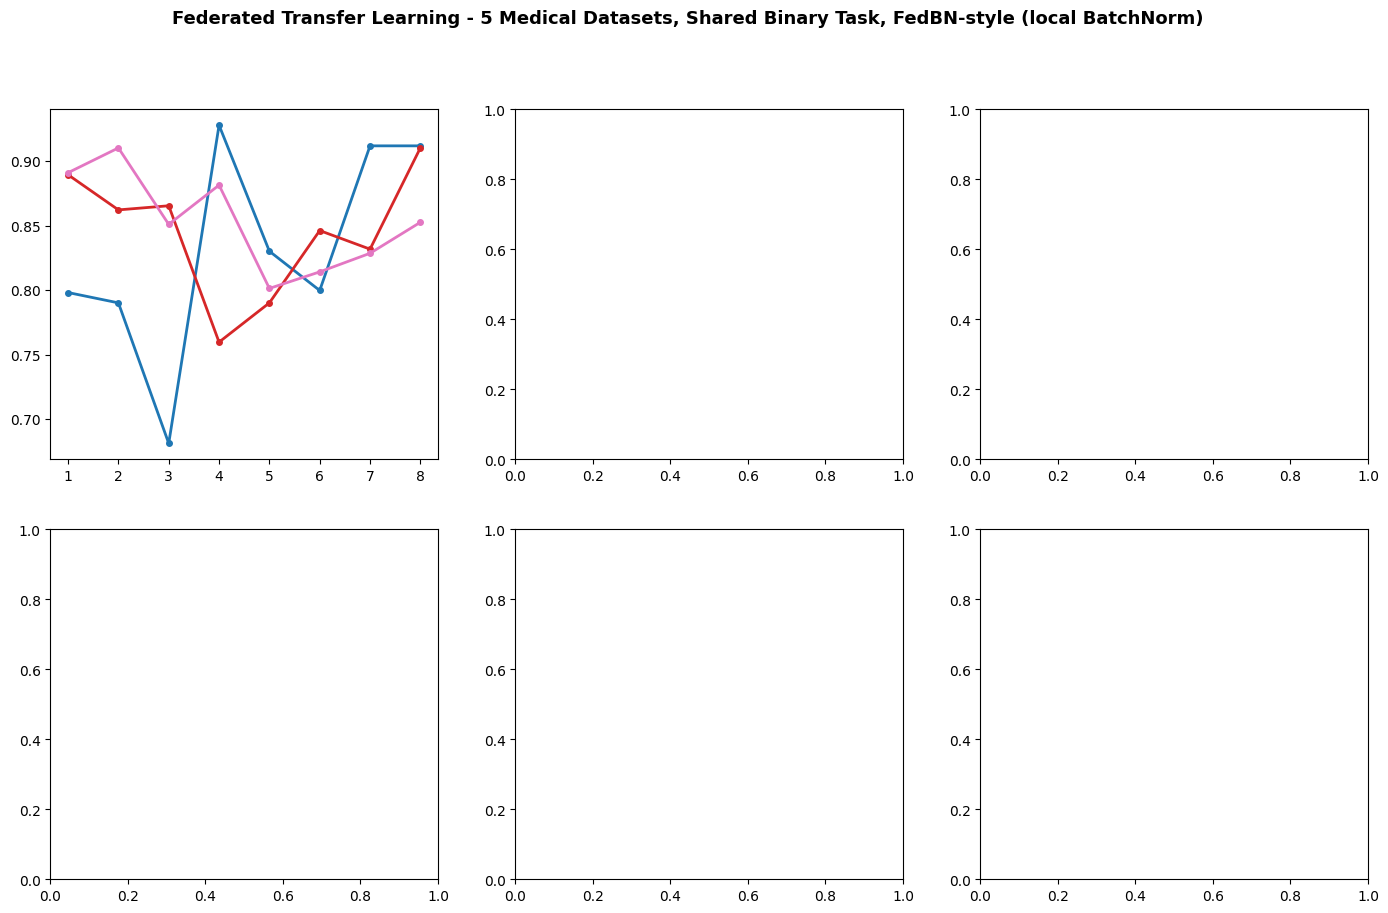

In [10]:
results = {
    'FedAvg'          : history_fedavg,
    'FedProx'         : history_fedprox,
    'FedAdam'         : history_fedadam,
    'FedDistillation' : history_feddistill,
}

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
fig.suptitle('Federated Transfer Learning - 5 Medical Datasets, Shared Binary Task, FedBN-style (local BatchNorm)',
             fontsize=13, fontweight='bold')
axes = axes.flatten()
palette = plt.cm.tab10(np.linspace(0, 1, 4))

for ax, name in zip(axes, client_names):
    for (algo, hist), color in zip(results.items(), palette):
        ax.plot(hist['round'], hist[name], '-o', lw=2, ms=4, color=color, label=algo)
    ax.set(xlabel='Round', ylabel='Test Accuracy', title=name)
    ax.legend(fontsize=7); ax.grid(alpha=0.3); ax.set_ylim(0, 1.05)

for (algo, hist), color in zip(results.items(), palette):
    mean_per_round = [np.mean([hist[n][r] for n in client_names]) for r in range(CONFIG['num_rounds'])]
    axes[5].plot(range(1, CONFIG['num_rounds']+1), mean_per_round, '-o', lw=2, ms=4, color=color, label=algo)
axes[5].set(xlabel='Round', ylabel='Mean Accuracy Across 5 Clients', title='Mean Across All Clients')
axes[5].legend(fontsize=7); axes[5].grid(alpha=0.3); axes[5].set_ylim(0, 1.05)

plt.tight_layout()
plt.savefig('binary_multi_medical_ftl_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved as binary_multi_medical_ftl_comparison.png')

print('\nFinal round accuracy - Algorithm x Client (and mean):')
header = f'{"Algorithm":16s} | ' + ' | '.join(f'{n[:13]:13s}' for n in client_names) + ' | Mean'
print(header); print('=' * len(header))
for algo, hist in results.items():
    row_vals = [hist[name][-1] for name in client_names]
    print(f'{algo:16s} | ' + ' | '.join(f'{v:13.4f}' for v in row_vals) + f' | {np.mean(row_vals):.4f}')


---
## Section 9: Summary

**Two fixes were applied during this experiment, in order:**
1. Unfreezing the backbone (instead of a frozen linear probe) so the network could actually learn
   medical-image-relevant features instead of relying on unrelated, frozen, natural-image ImageNet features.
2. Excluding BatchNorm layers from federation entirely (the FedBN fix), because averaging BatchNorm
   statistics across 5 very different medical imaging domains caused the whole model to collapse into
   predicting a fixed, majority-class answer regardless of the input image.

**What to check in the results above:** does each client's own accuracy (using its federated backbone plus
its own local BatchNorm) now land closer to normal published benchmark numbers, especially for
PneumoniaMNIST and BreastMNIST, which have well known reference accuracies in the 85 to 90 percent range?
RetinaMNIST is expected to remain the hardest client even after both fixes, since diabetic retinopathy
grading is a genuinely difficult task even in dedicated, non-federated benchmarks.

**What to tell your professor:**
> *"My first version had unusually low accuracy because I was using a fully frozen pretrained backbone,
> which cannot adapt to medical images at all. Fixing that caused a second, more subtle problem:
> federating BatchNorm statistics across five very different medical imaging domains made the whole model
> collapse into always predicting the majority class, which I diagnosed by noticing the final accuracies
> exactly matched each dataset's class balance. I fixed this using the approach from FedBN (Li et al.,
> 2021, ICLR), which keeps BatchNorm layers local to each client instead of averaging them, and is
> specifically designed for federated learning across different medical imaging scanners and domains."*
